# Low-Rank Gaussian (Laplace) Approximation Tutorial

This tutorial demonstrates `ls_bayesian`'s `lowrank` subpackage on a small linear inverse problem
that is cheap enough to be compared against the exact dense posterior. It shows how to

1. wrap a prior as a [`ReferenceCovariance`][ls_bayesian.lowrank.interfaces.ReferenceCovariance],
2. compute the dominant eigenpairs of the data-misfit (Gauss-Newton) Hessian relative to the prior
   precision with `compute_generalized_eigenpairs` and either of its two solvers, and
3. assemble them into a `LowRankGaussian`, from which we apply the covariance, draw samples, and
   compute pointwise variances and the log-determinant ratio.

The subpackage is self-contained: it only needs callables for the Hessian action and the prior
operators, and knows nothing about posteriors, FEM, or MCMC.

## Mathematical Formulation

Let $H$ be the Gauss-Newton Hessian of the data misfit at the MAP point $\bar m$ and
$\Gamma_0$ the prior covariance with precision $Q = \Gamma_0^{-1}$. The Laplace approximation of the
posterior is $\mathcal N(\bar m, (H + Q)^{-1})$. Since $H$ typically has only few eigenvalues that are
large compared to the prior, we solve the generalized eigenvalue problem

$$
H v_i = \lambda_i Q v_i, \qquad v_i^T Q v_j = \delta_{ij},
$$

for the $r$ largest $\lambda_i$ (Bui-Thanh, Ghattas, Martin, Stadler, 2013; Villa, Petra, Ghattas,
2021). Here $\lambda_i$ measures how much more the data informs direction $v_i$ than the prior. With
$H \approx Q V \Lambda V^T Q$, the Sherman-Morrison-Woodbury identity yields

$$
\Gamma_\text{post} \approx \Gamma_0 - V \,\mathrm{diag}\!\left(\frac{\lambda_i}{1+\lambda_i}\right) V^T,
\qquad
\log\det\Gamma_\text{post} - \log\det\Gamma_0 = -\sum_i \log(1+\lambda_i).
$$

Only the $r$ eigenpairs have to be computed, with matrix-free products of $H$, $Q$ and $Q^{-1}$.

## Imports and Configuration

We use NumPy and SciPy for the (dense) reference computations, Matplotlib for the plots, and the
`interfaces`, `eigensolvers` and `gaussian` modules of `ls_bayesian`'s `lowrank` subpackage. All
randomness is seeded.

In [1]:
from typing import override

import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg

from ls_bayesian.lowrank.eigensolvers import (
    GeneralizedEigenpairs,
    LanczosSolver,
    RandomizedDoublePassSolver,
    compute_generalized_eigenpairs,
)
from ls_bayesian.lowrank.gaussian import LowRankGaussian
from ls_bayesian.lowrank.interfaces import ReferenceCovariance

SEED = 0
NUM_NODES = 200
NUM_OBSERVATIONS = 20
NOISE_STANDARD_DEVIATION = 0.05
PRIOR_INVERSE_CORRELATION_LENGTH = 10.0
OBSERVATION_KERNEL_WIDTH = 0.03
NUM_EIGENVALUES = 20
NUM_SAMPLES = 2000

rng = np.random.default_rng(SEED)

## Prior

We discretize a one-dimensional field on $[0, 1]$ with a Bilaplacian-type prior, the same structure
as the `spde_prior` subpackage's, but with finite differences on a uniform grid (lumped mass matrix
$M$, stiffness matrix $K$, SPDE matrix $A = \kappa^2 M + K$). The coefficient covariance is
$\Gamma_0 = A^{-1} M A^{-1}$, with precision $Q = A M^{-1} A$ and the sampling factor $\widehat\Gamma_0 =
A^{-1}M^{1/2}$. A constant rescales the marginal standard deviation to 1 at the center.

The `ReferenceCovariance` adapter below is all that connects this prior to `lowrank`. Its factor is
deliberately non-symmetric, as the interface only requires $\widehat\Gamma_0\widehat\Gamma_0^T =
\Gamma_0$.

In [2]:
nodes = np.linspace(0.0, 1.0, NUM_NODES)
spacing = nodes[1] - nodes[0]
mass_matrix = spacing * np.eye(NUM_NODES)
stiffness_matrix = (
    2.0 * np.eye(NUM_NODES) - np.eye(NUM_NODES, k=1) - np.eye(NUM_NODES, k=-1)
) / spacing
stiffness_matrix[0, 0] = stiffness_matrix[-1, -1] = 1.0 / spacing
spde_matrix = PRIOR_INVERSE_CORRELATION_LENGTH**2 * mass_matrix + stiffness_matrix

spde_matrix_inverse = np.linalg.inv(spde_matrix)
unscaled_factor = spde_matrix_inverse @ np.sqrt(mass_matrix)
scaling = 1.0 / (unscaled_factor @ unscaled_factor.T)[NUM_NODES // 2, NUM_NODES // 2]

prior_factor = np.sqrt(scaling) * unscaled_factor
prior_covariance = prior_factor @ prior_factor.T
prior_precision = np.linalg.inv(prior_covariance)


class BilaplacianReference(ReferenceCovariance):
    # Dense finite-difference Bilaplacian prior covariance, Gamma_0 = A^{-1} M A^{-1}

    @property
    @override
    def random_vector_size(self) -> int:
        return prior_factor.shape[1]

    @override
    def apply_covariance_factorization(self, random_vector: np.ndarray) -> np.ndarray:
        return prior_factor @ random_vector

    @override
    def apply_covariance_operator(self, vector: np.ndarray) -> np.ndarray:
        return prior_covariance @ vector

    @override
    def apply_precision_operator(self, vector: np.ndarray) -> np.ndarray:
        return prior_precision @ vector


prior = BilaplacianReference()

## Forward Problem and Data

The parameter-to-observable map is linear, $d = Om + \varepsilon$ with $\varepsilon \sim
\mathcal N(0, \sigma^2 I)$. $O$ averages the field with a narrow Gaussian kernel around 20 observation
points, so the data constrain only a few smooth directions of the parameter. For a linear map the
Gauss-Newton Hessian $H = J^T \Gamma_\varepsilon^{-1} J$ with $J = O$ is the exact Hessian, and the
posterior is Gaussian. We can therefore compare the low-rank approximation with the exact posterior,
and the MAP point is $\bar m = \Gamma_\text{post}O^T\Gamma_\varepsilon^{-1}d$.

The Hessian is only exposed to the eigensolvers as a matrix-free product, composed of a Jacobian
product, the noise precision, and a transposed Jacobian product, as it would be for a PDE-based map.

In [3]:
observation_points = np.linspace(0.05, 0.95, NUM_OBSERVATIONS)
observation_matrix = (
    spacing
    * np.exp(-0.5 * ((observation_points[:, None] - nodes[None, :]) / OBSERVATION_KERNEL_WIDTH) ** 2)
    / (OBSERVATION_KERNEL_WIDTH * np.sqrt(2.0 * np.pi))
)

true_parameter = np.sin(2.0 * np.pi * nodes) + 0.5 * np.exp(-(((nodes - 0.7) / 0.05) ** 2))
data = observation_matrix @ true_parameter + NOISE_STANDARD_DEVIATION * rng.standard_normal(
    NUM_OBSERVATIONS
)


def apply_jacobian(direction: np.ndarray) -> np.ndarray:
    return observation_matrix @ direction


def apply_jacobian_transpose(adjoint: np.ndarray) -> np.ndarray:
    return observation_matrix.T @ adjoint


def apply_noise_precision(vector: np.ndarray) -> np.ndarray:
    return vector / NOISE_STANDARD_DEVIATION**2


def apply_gauss_newton_hessian(direction: np.ndarray) -> np.ndarray:
    return apply_jacobian_transpose(apply_noise_precision(apply_jacobian(direction)))

## Exact Reference Posterior

For the comparison only, we assemble the dense Hessian and the exact posterior. A real application
never forms these matrices.

In [4]:
dense_hessian = np.column_stack(
    [apply_gauss_newton_hessian(column) for column in np.eye(NUM_NODES)]
)
exact_posterior_covariance = np.linalg.inv(prior_precision + dense_hessian)
exact_map_estimate = exact_posterior_covariance @ apply_jacobian_transpose(
    apply_noise_precision(data)
)
exact_posterior_variance = np.diag(exact_posterior_covariance)
prior_variance = np.diag(prior_covariance)

dense_eigenvalues = scipy.linalg.eigh(dense_hessian, prior_precision, eigvals_only=True)[::-1]
print(f"Largest eigenvalues of H v = lambda Q v: {dense_eigenvalues[:5]}")
print(f"Number of eigenvalues above 1 (data-dominated directions): {np.sum(dense_eigenvalues > 1)}")

Largest eigenvalues of H v = lambda Q v: [3186.80604405 2445.57962126 1457.39357532  756.57674032  379.1695608 ]
Number of eigenvalues above 1 (data-dominated directions): 15


## Generalized Eigenvalue Problem

`compute_generalized_eigenpairs` takes the three matrix-free actions $H$, $Q$ and $Q^{-1}$ and a solver
strategy. Both algorithms need $Q^{-1}$:

- `LanczosSolver`: implicitly restarted Lanczos (ARPACK via `scipy.sparse.linalg.eigsh`) in the
  $Q$-inner product. It uses sequential products and few of them for a quickly decaying spectrum.
- `RandomizedDoublePassSolver`: randomized double-pass algorithm (Saibaba, Lee, Kitanidis, 2016, as
  in hIPPYlib) with a fixed number $2(k + p)$ of Hessian products that could be batched, where $p$
  is the oversampling.

Pairs with $\lambda \le$ `minimum_eigenvalue` are discarded. They carry no information on the data
and appear as rounding noise if the Hessian has a lower rank than requested.

In [5]:
def solve_eigenproblem(solver):
    return compute_generalized_eigenpairs(
        hessian_action=apply_gauss_newton_hessian,
        precision_action=prior.apply_precision_operator,
        covariance_action=prior.apply_covariance_operator,
        size=NUM_NODES,
        num_eigenvalues=NUM_EIGENVALUES,
        solver=solver,
        minimum_eigenvalue=1e-8,
    )


lanczos_pairs = solve_eigenproblem(LanczosSolver(seed=SEED))
double_pass_pairs = solve_eigenproblem(RandomizedDoublePassSolver(oversampling=5, seed=SEED))

for name, pairs in [("Lanczos", lanczos_pairs), ("Double pass", double_pass_pairs)]:
    relative_error = np.abs(pairs.eigenvalues / dense_eigenvalues[: pairs.eigenvalues.size] - 1.0)
    orthonormality_error = np.linalg.norm(
        pairs.eigenvectors.T @ prior_precision @ pairs.eigenvectors - np.eye(pairs.eigenvalues.size)
    )
    print(
        f"{name}: {pairs.eigenvalues.size} pairs, max relative eigenvalue error "
        f"{relative_error.max():.1e}, Q-orthonormality error {orthonormality_error:.1e}"
    )

Lanczos: 20 pairs, max relative eigenvalue error 5.6e-08, Q-orthonormality error 7.2e-11
Double pass: 20 pairs, max relative eigenvalue error 5.6e-08, Q-orthonormality error 5.5e-11


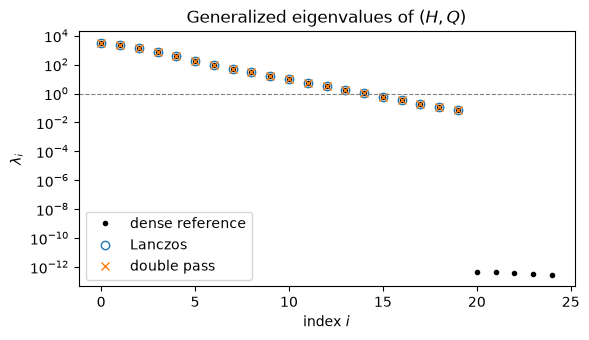

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(dense_eigenvalues[: NUM_OBSERVATIONS + 5], "k.", label="dense reference")
ax.semilogy(lanczos_pairs.eigenvalues, "o", mfc="none", label="Lanczos")
ax.semilogy(double_pass_pairs.eigenvalues, "x", label="double pass")
ax.axhline(1.0, color="gray", ls="--", lw=0.8)
ax.set(xlabel="index $i$", ylabel=r"$\lambda_i$", title="Generalized eigenvalues of $(H, Q)$")
ax.legend()
fig.tight_layout()

Only about as many eigenvalues as there are observations are non-zero, and the spectrum decays
rapidly. Both solvers reproduce the dominant part of the dense spectrum, and the $Q$-orthonormality of
the eigenvectors the covariance formulas rely on.

## The Low-Rank Gaussian

`LowRankGaussian` combines the reference covariance and the eigenpairs. The mean defaults to zero, which
is the prior mean here and lets us compute the MAP point through the low-rank covariance, $\bar m =
\Gamma_\text{post} O^T \Gamma_\varepsilon^{-1} d$. We then re-create the Gaussian with the MAP point as
its mean, which makes it the Laplace approximation.

In [7]:
zero_mean_gaussian = LowRankGaussian(prior, lanczos_pairs)
map_estimate = zero_mean_gaussian.apply_covariance_operator(
    apply_jacobian_transpose(apply_noise_precision(data))
)
posterior = LowRankGaussian(prior, lanczos_pairs, mean=map_estimate, seed=SEED)

map_error = np.linalg.norm(map_estimate - exact_map_estimate) / np.linalg.norm(exact_map_estimate)
print(f"Relative error of the MAP point from the low-rank covariance: {map_error:.1e}")

low_rank_variance = posterior.compute_pointwise_variance(prior_variance=prior_variance)
variance_error = np.max(np.abs(low_rank_variance - exact_posterior_variance) / exact_posterior_variance)
print(f"Max relative error of the pointwise variance: {variance_error:.1e}")

estimated_variance = posterior.compute_pointwise_variance(num_probes=1000, seed=SEED)
estimator_error = np.max(np.abs(estimated_variance - exact_posterior_variance))
print(
    "Max absolute error with a probe-estimated prior variance (1000 probes): "
    f"{estimator_error:.1e}, for a prior variance of 1"
)

_, log_det_posterior = np.linalg.slogdet(exact_posterior_covariance)
_, log_det_prior = np.linalg.slogdet(prior_covariance)
log_determinant_ratio = posterior.compute_log_determinant_ratio()
print(
    f"log det ratio: {log_determinant_ratio:.6f} "
    f"(dense: {log_det_posterior - log_det_prior:.6f})"
)

Relative error of the MAP point from the low-rank covariance: 3.7e-08
Max relative error of the pointwise variance: 4.3e-09
Max absolute error with a probe-estimated prior variance (1000 probes): 7.3e-01, for a prior variance of 1
log det ratio: -64.513781 (dense: -64.513781)


The pointwise variance is exact in the low-rank part, and matches the dense reference once the
data-informed directions are captured. If the prior variance is not known, it can be estimated with
probing vectors (Bekas, Kokiopoulou, Saad, 2007), the fallback for large problems. The estimator is
unbiased, but its standard error is governed by the off-diagonal entries of $\Gamma_0$, so for a
smooth, strongly correlated prior like this one it remains inaccurate even with 1000 probes (compare
with the exact value above). Prefer an exact prior diagonal where it is available, e.g. from the
prior's own structure. Truncating a spectral representation of the prior is not a substitute, as it
underestimates the variance by the discarded tail.

We now draw samples with `generate_sample`, which uses the sampling factor $\widehat\Gamma =
(I - V\,\mathrm{diag}(1 - (1+\lambda_i)^{-1/2}) V^T Q)\widehat\Gamma_0$ and compare the pointwise
credible band of the field with the exact posterior and the prior.

Max relative error of the sample variance (2000 samples): 0.07 (per-node Monte Carlo error is about 0.03)


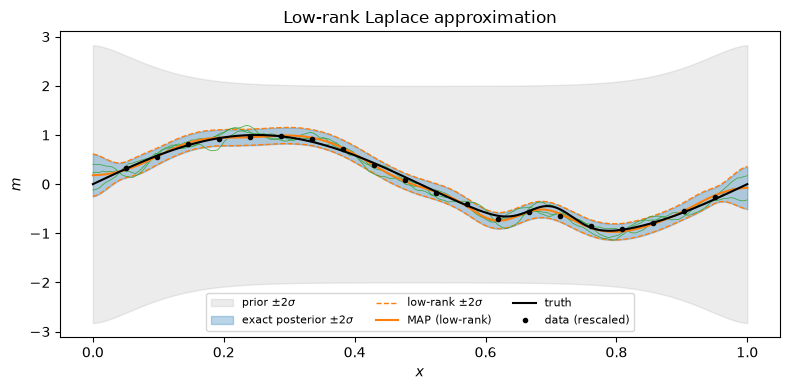

In [8]:
samples = np.array([posterior.generate_sample() for _ in range(NUM_SAMPLES)])
sample_variance_error = np.max(
    np.abs(samples.var(axis=0, ddof=1) / exact_posterior_variance - 1.0)
)
print(
    f"Max relative error of the sample variance ({NUM_SAMPLES} samples): "
    f"{sample_variance_error:.2f} (per-node Monte Carlo error is about {np.sqrt(2 / NUM_SAMPLES):.2f})"
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.fill_between(nodes, -2 * np.sqrt(prior_variance), 2 * np.sqrt(prior_variance),
                color="gray", alpha=0.15, label=r"prior $\pm 2\sigma$")
ax.fill_between(nodes, exact_map_estimate - 2 * np.sqrt(exact_posterior_variance),
                exact_map_estimate + 2 * np.sqrt(exact_posterior_variance),
                color="C0", alpha=0.3, label=r"exact posterior $\pm 2\sigma$")
ax.plot(nodes, map_estimate - 2 * np.sqrt(low_rank_variance), "C1--", lw=1,
        label=r"low-rank $\pm 2\sigma$")
ax.plot(nodes, map_estimate + 2 * np.sqrt(low_rank_variance), "C1--", lw=1)
ax.plot(nodes, samples[:3].T, color="C2", lw=0.6, alpha=0.8)
ax.plot(nodes, map_estimate, "C1", label="MAP (low-rank)")
ax.plot(nodes, true_parameter, "k", label="truth")
ax.plot(observation_points, data / observation_matrix.sum(axis=1), "k.", label="data (rescaled)")
ax.set(xlabel="$x$", ylabel="$m$", title="Low-rank Laplace approximation")
ax.legend(ncols=3, fontsize=8)
fig.tight_layout()

The low-rank band is indistinguishable from the exact one. Far from data, the posterior reverts to
the prior band; near observations, it contracts. The green lines are three individual posterior samples.

## Effect of the Rank

The rank is the only approximation parameter. Truncating the computed pairs after $r$ eigenvalues shows
how the error decays with the discarded $\lambda_i / (1 + \lambda_i)$ weights.

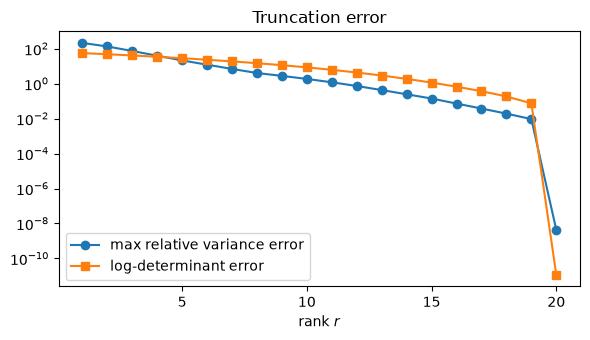

In [9]:
ranks = np.arange(1, lanczos_pairs.eigenvalues.size + 1)
variance_errors = np.empty(ranks.size)
log_determinant_errors = np.empty(ranks.size)
for index, rank in enumerate(ranks):
    truncated = LowRankGaussian(
        prior,
        GeneralizedEigenpairs(lanczos_pairs.eigenvalues[:rank], lanczos_pairs.eigenvectors[:, :rank]),
    )
    truncated_variance = truncated.compute_pointwise_variance(prior_variance=prior_variance)
    variance_errors[index] = np.max(
        np.abs(truncated_variance - exact_posterior_variance) / exact_posterior_variance
    )
    log_determinant_errors[index] = np.abs(
        truncated.compute_log_determinant_ratio() - (log_det_posterior - log_det_prior)
    )

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogy(ranks, variance_errors, "o-", label="max relative variance error")
ax.semilogy(ranks, log_determinant_errors, "s-", label="log-determinant error")
ax.set(xlabel="rank $r$", title="Truncation error")
ax.xaxis.get_major_locator().set_params(integer=True)
ax.legend()
fig.tight_layout()

## Summary

- `compute_generalized_eigenpairs` needs only matrix-free products with $H$, $Q$ and $Q^{-1}$ plus a
  solver strategy (`LanczosSolver` or `RandomizedDoublePassSolver`); both reproduced the dense
  spectrum of the toy problem.
- `LowRankGaussian` provides the covariance, precision, sampling factor, potential, pointwise variance
  and log-determinant ratio of $\mathcal N(\bar m, \Gamma_0 - VDV^T)$. The mean defaults to zero and is
  set to the MAP point for a Laplace approximation.
- The error is controlled by the rank: it decreases as the weights $\lambda_i/(1+\lambda_i)$ of the
  discarded directions fall, and vanishes up to solver accuracy at the rank of the Hessian, here the
  number of observations. Directions with $\lambda_i < 1$ still matter for accurate variances.
- The approximation assumes that $H$ and $Q$ are expressed in the same (coefficient) space and that
  $\Gamma_0$ and $Q$ are exact inverses of each other, up to the tolerance of the eigensolver.